In [17]:
# ============================================================
# FINAL OPTIMIZED DRUG REPURPOSING XGBOOST
# Problem: Predicting New Diseases Using Drug Repurposing
# ============================================================

!pip -q install xgboost rdkit scikit-learn pandas numpy

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier


# ============================================================
# 1. LOAD DATA
# ============================================================

mapping_df = pd.read_csv("mapping.csv")
drugs_df = pd.read_csv("drugsInfo.csv")
diseases_df = pd.read_csv("diseasesInfo.csv")

print("Dataset sizes:")
print("Mapping :", mapping_df.shape)
print("Drugs   :", drugs_df.shape)
print("Diseases:", diseases_df.shape)

df = (
    mapping_df
    .merge(drugs_df, on="DrugID")
    .merge(diseases_df, on="DiseaseID")
)

print("Merged:", df.shape)


# ============================================================
# 2. REMOVE LEAKAGE-PRONE / INVALID ROWS
# ============================================================

# IMPORTANT:
# Do NOT use DrugConditions or other fields containing known
# indications/conditions as model features.

df = df.dropna(subset=["DrugSmile", "DiseaseName"]).copy()

df["DrugSmile"] = df["DrugSmile"].astype(str)
df["DiseaseName"] = df["DiseaseName"].astype(str)

# Parse molecules
df["mol"] = df["DrugSmile"].apply(Chem.MolFromSmiles)

df = df[df["mol"].notna()].copy()

print("Valid molecular rows:", len(df))
print("Valid drugs:", df["DrugID"].nunique())
print("Diseases:", df["DiseaseID"].nunique())


# ============================================================
# 3. SELECT THE 20 MOST REPRESENTED DISEASES
# ============================================================

top_diseases = (
    df["DiseaseName"]
    .value_counts()
    .head(20)
    .index
    .tolist()
)

df = df[df["DiseaseName"].isin(top_diseases)].copy()

print("\nDiseases used:")
print(df["DiseaseName"].value_counts())


# ============================================================
# 4. UNIQUE DRUG TABLE
# ============================================================

drug_table = (
    df[["DrugID", "DrugSmile", "mol"]]
    .drop_duplicates("DrugID")
    .reset_index(drop=True)
)

drug_ids = drug_table["DrugID"].tolist()
drug_to_idx = {d: i for i, d in enumerate(drug_ids)}

print("\nUnique drugs:", len(drug_table))


# ============================================================
# 5. MORGAN FINGERPRINT + ENHANCED DESCRIPTORS
# ============================================================

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=512
)

descriptor_functions = [
    Descriptors.MolWt,
    Descriptors.MolLogP,
    Descriptors.TPSA,
    Descriptors.NumHDonors,
    Descriptors.NumHAcceptors,
    Descriptors.NumRotatableBonds,
    Descriptors.RingCount,
    Descriptors.NumAromaticRings,
    Descriptors.NumAliphaticRings,
    Descriptors.FractionCSP3,
    Descriptors.HeavyAtomCount,
    Descriptors.NHOHCount,
    Descriptors.NOCount,
    Descriptors.NumHeteroatoms,
    Descriptors.NumSaturatedRings,
    Descriptors.NumAliphaticHeterocycles
]

drug_features = {}

for _, row in drug_table.iterrows():

    drug_id = row["DrugID"]
    mol = row["mol"]

    fp = morgan_generator.GetFingerprint(mol)

    fp_array = np.zeros(512, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, fp_array)

    desc = []

    for func in descriptor_functions:
        try:
            value = func(mol)
            if not np.isfinite(value):
                value = 0.0
        except:
            value = 0.0

        desc.append(float(value))

    desc = np.array(desc, dtype=np.float32)

    # Log-transform some heavily skewed descriptors
    desc[0] = np.log1p(max(desc[0], 0))
    desc[1] = np.clip(desc[1], -10, 10)
    desc[2] = np.log1p(max(desc[2], 0))

    drug_features[drug_id] = np.concatenate([fp_array, desc])


drug_feature_matrix = np.vstack(
    [drug_features[d] for d in drug_ids]
)

print("Drug feature size:", drug_feature_matrix.shape[1])


# ============================================================
# 6. DISEASE TEXT FEATURES
# ============================================================

disease_text = (
    df[["DiseaseID", "DiseaseName", "DiseaseDescription"]]
    .drop_duplicates("DiseaseID")
    .copy()
)

disease_text["DiseaseDescription"] = (
    disease_text["DiseaseDescription"]
    .fillna("")
    .astype(str)
)

disease_text["text"] = (
    disease_text["DiseaseName"].fillna("").astype(str)
    + " "
    + disease_text["DiseaseDescription"]
)

tfidf = TfidfVectorizer(
    max_features=256,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

disease_matrix = tfidf.fit_transform(
    disease_text["text"]
).toarray().astype(np.float32)

disease_id_to_vec = {
    disease_id: disease_matrix[i]
    for i, disease_id in enumerate(disease_text["DiseaseID"])
}

print("Disease feature size:", disease_matrix.shape[1])


# ============================================================
# 7. DISEASE INDEX
# ============================================================

selected_disease_ids = (
    df[["DiseaseID", "DiseaseName"]]
    .drop_duplicates()
    ["DiseaseID"]
    .tolist()
)

disease_name_map = (
    df[["DiseaseID", "DiseaseName"]]
    .drop_duplicates()
    .set_index("DiseaseID")["DiseaseName"]
    .to_dict()
)

disease_ids = selected_disease_ids

disease_to_idx = {
    d: i for i, d in enumerate(disease_ids)
}


# ============================================================
# 8. POSITIVE ASSOCIATIONS
# ============================================================

positive_pairs = (
    df[["DrugID", "DiseaseID"]]
    .drop_duplicates()
)

positive_set = set(
    zip(
        positive_pairs["DrugID"],
        positive_pairs["DiseaseID"]
    )
)

print("\nPositive associations:", len(positive_pairs))


# ============================================================
# 9. CREATE BALANCED DATASET
# ============================================================

# Positive examples
positive_examples = positive_pairs.copy()
positive_examples["label"] = 1


# Candidate negative pairs
rng = np.random.RandomState(42)

all_drugs = drug_ids
all_diseases = disease_ids

negative_pairs = []

positive_count = len(positive_examples)

while len(negative_pairs) < positive_count:

    d = rng.choice(all_drugs)
    dis = rng.choice(all_diseases)

    if (d, dis) not in positive_set:
        negative_pairs.append((d, dis))

negative_examples = pd.DataFrame(
    negative_pairs,
    columns=["DrugID", "DiseaseID"]
)

negative_examples["label"] = 0

data = pd.concat(
    [positive_examples, negative_examples],
    ignore_index=True
)

data = data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\nBalanced dataset:")
print("Total   :", len(data))
print("Positive:", (data["label"] == 1).sum())
print("Negative:", (data["label"] == 0).sum())


# ============================================================
# 10. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    stratify=data["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("\nSplit:")
print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))


# ============================================================
# 11. TRAINING-ONLY NETWORK FEATURES
# ============================================================

train_positive = train_df[
    train_df["label"] == 1
][["DrugID", "DiseaseID"]]

train_positive_set = set(
    zip(
        train_positive["DrugID"],
        train_positive["DiseaseID"]
    )
)

# Drug degree
train_drug_degree = (
    train_positive
    .groupby("DrugID")
    .size()
    .to_dict()
)

# Disease degree
train_disease_degree = (
    train_positive
    .groupby("DiseaseID")
    .size()
    .to_dict()
)

# Drug -> known diseases
drug_known_diseases = {}

for drug, disease in train_positive_set:
    drug_known_diseases.setdefault(drug, set()).add(disease)


# ============================================================
# 12. PRECOMPUTE MORGAN FINGERPRINTS
# ============================================================

drug_fps = {}

for drug_id, features in drug_features.items():

    mol = drug_table.loc[
        drug_table["DrugID"] == drug_id,
        "mol"
    ].iloc[0]

    drug_fps[drug_id] = morgan_generator.GetFingerprint(mol)


# ============================================================
# 13. BUILD INTERACTION FEATURES
# ============================================================

def build_features(input_df):

    rows = []

    for _, row in input_df.iterrows():

        drug = row["DrugID"]
        disease = row["DiseaseID"]

        dvec = drug_features[drug]
        disease_vec = disease_id_to_vec.get(
            disease,
            np.zeros(256, dtype=np.float32)
        )

        # Morgan portion
        fingerprint = dvec[:512]

        # Molecular / disease interaction
        interaction = (
            fingerprint[:256] *
            disease_vec[:256]
        )

        # Similarity to known drugs for this disease
        max_similarity = 0.0
        mean_similarity = 0.0
        similarity_count = 0

        known_diseases = drug_known_diseases.get(
            drug, set()
        )

        # Similarity against drugs known for this disease
        known_drugs_for_disease = [
            x for x, y in train_positive_set
            if y == disease
        ]

        if known_drugs_for_disease:

            sims = []

            fp1 = drug_fps[drug]

            for other_drug in known_drugs_for_disease[:50]:

                if other_drug == drug:
                    continue

                sim = DataStructs.TanimotoSimilarity(
                    fp1,
                    drug_fps[other_drug]
                )

                sims.append(sim)

            if sims:
                max_similarity = max(sims)
                mean_similarity = float(np.mean(sims))
                similarity_count = len(sims)

        # Network features
        drug_degree = train_drug_degree.get(drug, 0)
        disease_degree = train_disease_degree.get(disease, 0)

        # Log-scaled degree
        log_drug_degree = np.log1p(drug_degree)
        log_disease_degree = np.log1p(disease_degree)

        # Pairwise statistics
        degree_product = (
            log_drug_degree *
            log_disease_degree
        )

        degree_ratio = (
            log_drug_degree /
            (log_disease_degree + 1e-6)
        )

        feature_vector = np.concatenate([
            dvec,
            disease_vec,
            interaction,

            np.array([
                max_similarity,
                mean_similarity,
                similarity_count,
                log_drug_degree,
                log_disease_degree,
                degree_product,
                degree_ratio,
                len(known_diseases),
                float(drug_degree > 0),
                float(disease_degree > 0)
            ], dtype=np.float32)
        ])

        rows.append(feature_vector)

    return np.vstack(rows).astype(np.float32)


print("\nBuilding training features...")

X_train = build_features(train_df)

print("Building validation features...")

X_val = build_features(val_df)

print("Building test features...")

X_test = build_features(test_df)

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

print("\nFeature matrices:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)


# ============================================================
# 14. HYPERPARAMETER SEARCH
# ============================================================

parameter_sets = [

    {
        "max_depth": 4,
        "learning_rate": 0.025,
        "min_child_weight": 2,
        "gamma": 0.05,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.05,
        "reg_lambda": 2.0
    },

    {
        "max_depth": 5,
        "learning_rate": 0.025,
        "min_child_weight": 3,
        "gamma": 0.10,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.10,
        "reg_lambda": 2.0
    },

    {
        "max_depth": 6,
        "learning_rate": 0.02,
        "min_child_weight": 3,
        "gamma": 0.10,
        "subsample": 0.90,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.10,
        "reg_lambda": 2.5
    },

    {
        "max_depth": 5,
        "learning_rate": 0.02,
        "min_child_weight": 5,
        "gamma": 0.15,
        "subsample": 0.95,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.20,
        "reg_lambda": 3.0
    }
]


def find_best_threshold(y_true, prob):

    thresholds = np.arange(
        0.20,
        0.801,
        0.01
    )

    best = None

    for threshold in thresholds:

        pred = (
            prob >= threshold
        ).astype(int)

        acc = accuracy_score(y_true, pred)
        prec = precision_score(
            y_true, pred, zero_division=0
        )
        rec = recall_score(
            y_true, pred, zero_division=0
        )
        f1 = f1_score(
            y_true, pred, zero_division=0
        )

        cm = confusion_matrix(
            y_true, pred,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0 else 0
        )

        # Balanced objective.
        # Recall remains important for repurposing,
        # but we also reward accuracy, precision and specificity.
        score = (
            0.25 * acc +
            0.25 * f1 +
            0.20 * prec +
            0.15 * rec +
            0.15 * specificity
        )

        # Avoid extremely low-recall solutions
        if rec < 0.65:
            continue

        if best is None or score > best["score"]:

            best = {
                "threshold": threshold,
                "accuracy": acc,
                "precision": prec,
                "recall": rec,
                "f1": f1,
                "specificity": specificity,
                "score": score
            }

    return best


best_model = None
best_val_result = None
best_params = None

print("\n================================================")
print("XGBOOST HYPERPARAMETER SEARCH")
print("================================================")

for i, params in enumerate(parameter_sets, 1):

    print(
        f"\nTrial {i}/{len(parameter_sets)}"
    )
    print(params)

    model = XGBClassifier(
        n_estimators=1200,
        max_depth=params["max_depth"],
        learning_rate=params["learning_rate"],
        min_child_weight=params["min_child_weight"],
        gamma=params["gamma"],
        subsample=params["subsample"],
        colsample_bytree=params["colsample_bytree"],
        reg_alpha=params["reg_alpha"],
        reg_lambda=params["reg_lambda"],
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    val_prob = model.predict_proba(
        X_val
    )[:, 1]

    result = find_best_threshold(
        y_val,
        val_prob
    )

    print(
        f"Best threshold: {result['threshold']:.2f}"
    )
    print(
        f"Val Accuracy : {result['accuracy']:.4f}"
    )
    print(
        f"Val Precision: {result['precision']:.4f}"
    )
    print(
        f"Val Recall   : {result['recall']:.4f}"
    )
    print(
        f"Val F1       : {result['f1']:.4f}"
    )
    print(
        f"Val Specificity: {result['specificity']:.4f}"
    )

    if (
        best_val_result is None
        or result["score"] > best_val_result["score"]
    ):

        best_val_result = result
        best_model = model
        best_params = params.copy()


# ============================================================
# 15. FINAL VALIDATION RESULT
# ============================================================

threshold = best_val_result["threshold"]

print("\n================================================")
print("BEST MODEL")
print("================================================")

print("Parameters:")
print(best_params)

print(
    f"\nSelected threshold: {threshold:.2f}"
)

print(
    f"Validation Accuracy : "
    f"{best_val_result['accuracy']:.4f}"
)

print(
    f"Validation Precision: "
    f"{best_val_result['precision']:.4f}"
)

print(
    f"Validation Recall   : "
    f"{best_val_result['recall']:.4f}"
)

print(
    f"Validation F1       : "
    f"{best_val_result['f1']:.4f}"
)

print(
    f"Validation Specificity: "
    f"{best_val_result['specificity']:.4f}"
)


# ============================================================
# 16. FINAL TEST EVALUATION
# ============================================================

test_prob = best_model.predict_proba(
    X_test
)[:, 1]

test_pred = (
    test_prob >= threshold
).astype(int)

accuracy = accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    test_prob
)

pr_auc = average_precision_score(
    y_test,
    test_prob
)

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0 else 0
)


# ============================================================
# 17. FINAL RESULTS
# ============================================================

print("\n\n================================================")
print("FINAL TEST RESULTS")
print("================================================")

print(
    f"Threshold   : {threshold:.3f}"
)

print(
    f"Accuracy    : {accuracy:.4f}"
)

print(
    f"Precision   : {precision:.4f}"
)

print(
    f"Recall      : {recall:.4f}"
)

print(
    f"F1 Score    : {f1:.4f}"
)

print(
    f"ROC-AUC     : {roc_auc:.4f}"
)

print(
    f"PR-AUC      : {pr_auc:.4f}"
)

print(
    f"Specificity : {specificity:.4f}"
)

print("\nConfusion Matrix:")
print(cm)


# ============================================================
# 18. CLASSIFICATION REPORT
# ============================================================

print("\n\n================================================")
print("DETAILED CLASSIFICATION REPORT")
print("================================================")

report = classification_report(
    y_test,
    test_pred,
    target_names=[
        "No Association",
        "Association"
    ],
    digits=4,
    zero_division=0
)

print(report)


# ============================================================
# 19. PER-DISEASE REPORT
# ============================================================

test_eval = test_df.copy()

test_eval["probability"] = test_prob
test_eval["prediction"] = test_pred

per_disease = []

for disease_id, group in test_eval.groupby(
    "DiseaseID"
):

    if group["label"].nunique() < 2:
        continue

    acc = accuracy_score(
        group["label"],
        group["prediction"]
    )

    prec = precision_score(
        group["label"],
        group["prediction"],
        zero_division=0
    )

    rec = recall_score(
        group["label"],
        group["prediction"],
        zero_division=0
    )

    f1_d = f1_score(
        group["label"],
        group["prediction"],
        zero_division=0
    )

    per_disease.append({
        "Disease": disease_name_map.get(
            disease_id,
            str(disease_id)
        ),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1_d,
        "Support": len(group)
    })

per_disease_df = pd.DataFrame(
    per_disease
).sort_values(
    "F1",
    ascending=False
)

print("\n\n================================================")
print("PER-DISEASE PERFORMANCE")
print("================================================")

print(
    per_disease_df.to_string(
        index=False
    )
)


# ============================================================
# 20. SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{
    "Model": "Optimized XGBoost",
    "Threshold": threshold,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Specificity": specificity,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}])

metrics_df.to_csv(
    "final_drug_repurposing_metrics.csv",
    index=False
)

per_disease_df.to_csv(
    "final_per_disease_report.csv",
    index=False
)


# ============================================================
# 21. SAVE TEST PREDICTIONS
# ============================================================

test_output = test_df.copy()

test_output["PredictedProbability"] = test_prob
test_output["PredictedClass"] = test_pred

test_output["DiseaseName"] = (
    test_output["DiseaseID"]
    .map(disease_name_map)
)

test_output.to_csv(
    "final_drug_repurposing_predictions.csv",
    index=False
)


# ============================================================
# 22. GENERATE HIGH-CONFIDENCE REPURPOSING CANDIDATES
# ============================================================

# Only unseen associations
candidate_rows = []

for drug in drug_ids:

    for disease in disease_ids:

        if (drug, disease) in positive_set:
            continue

        candidate_rows.append({
            "DrugID": drug,
            "DiseaseID": disease
        })


# To avoid an enormous matrix in memory, process in chunks
candidate_scores = []

chunk_size = 10000

for start in range(
    0,
    len(candidate_rows),
    chunk_size
):

    chunk = pd.DataFrame(
        candidate_rows[start:start + chunk_size]
    )

    X_chunk = build_features(chunk)

    probs = best_model.predict_proba(
        X_chunk
    )[:, 1]

    chunk["PredictedProbability"] = probs

    candidate_scores.append(chunk)

candidate_df = pd.concat(
    candidate_scores,
    ignore_index=True
)

candidate_df["DiseaseName"] = (
    candidate_df["DiseaseID"]
    .map(disease_name_map)
)

candidate_df["DrugName"] = (
    candidate_df["DrugID"]
    .map(
        df.drop_duplicates("DrugID")
        .set_index("DrugID")["DrugName"]
        .to_dict()
    )
)

candidate_df = candidate_df.sort_values(
    "PredictedProbability",
    ascending=False
).reset_index(drop=True)

candidate_df.to_csv(
    "final_repurposing_candidates.csv",
    index=False
)

candidate_df.head(100).to_csv(
    "final_top_100_repurposing_candidates.csv",
    index=False
)


# ============================================================
# 23. SHOW TOP CANDIDATES
# ============================================================

print("\n\n================================================")
print("TOP REPURPOSING CANDIDATES")
print("================================================")

print(
    candidate_df[
        [
            "DrugName",
            "DiseaseName",
            "PredictedProbability"
        ]
    ]
    .head(20)
    .to_string(index=False)
)


# ============================================================
# 24. FINAL FILES
# ============================================================

print("\n\n================================================")
print("FILES CREATED")
print("================================================")

print("1. final_drug_repurposing_metrics.csv")
print("2. final_per_disease_report.csv")
print("3. final_drug_repurposing_predictions.csv")
print("4. final_repurposing_candidates.csv")
print("5. final_top_100_repurposing_candidates.csv")

print("\nDONE.")

Dataset sizes:
Mapping : (42200, 2)
Drugs   : (1410, 9)
Diseases: (1573, 5)
Merged: (42200, 14)
Valid molecular rows: 42200
Valid drugs: 1410
Diseases: 1573

Diseases used:
DiseaseName
Chemical and Drug Induced Liver Injury    459
Seizures                                  440
Hypertension                              402
Hypotension                               347
Pain                                      335
Nausea                                    332
Headache                                  318
Acute Kidney Injury                       288
Vomiting                                  281
Bradycardia                               278
Necrosis                                  272
Kidney Diseases                           256
Tachycardia                               245
Stevens-Johnson Syndrome                  238
Substance Withdrawal Syndrome             231
Depressive Disorder                       224
Fever                                     224
Edema                            

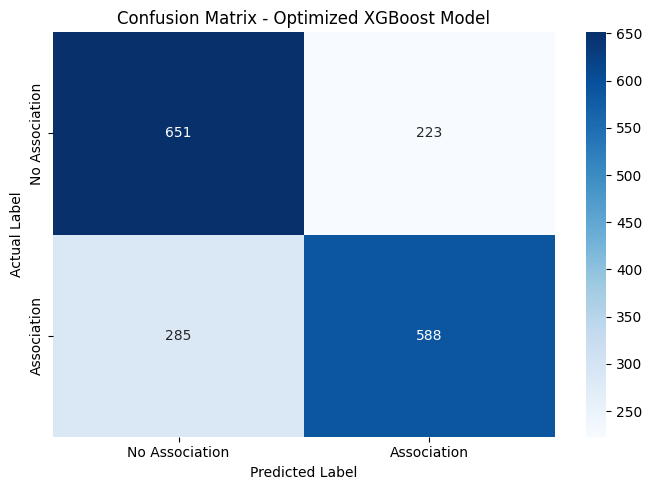

In [18]:
#confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Final test confusion matrix
cm = [[651, 223],
      [285, 588]]

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Association", "Association"],
    yticklabels=["No Association", "Association"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Optimized XGBoost Model")

plt.tight_layout()
plt.show()

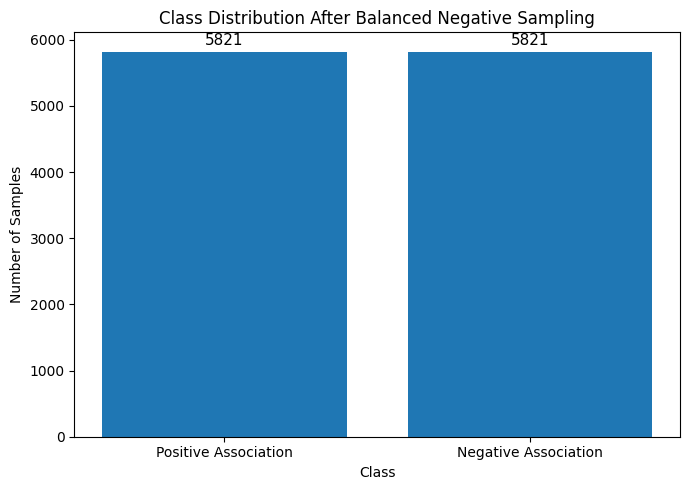

In [28]:
import matplotlib.pyplot as plt

# Class distribution after balancing
classes = ["Positive Association", "Negative Association"]
counts = [5821, 5821]

plt.figure(figsize=(7, 5))
plt.bar(classes, counts)

plt.title("Class Distribution After Balanced Negative Sampling")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

# Add values on top of bars
for i, value in enumerate(counts):
    plt.text(i, value + 100, str(value), ha="center", fontsize=11)

plt.tight_layout()
plt.show()

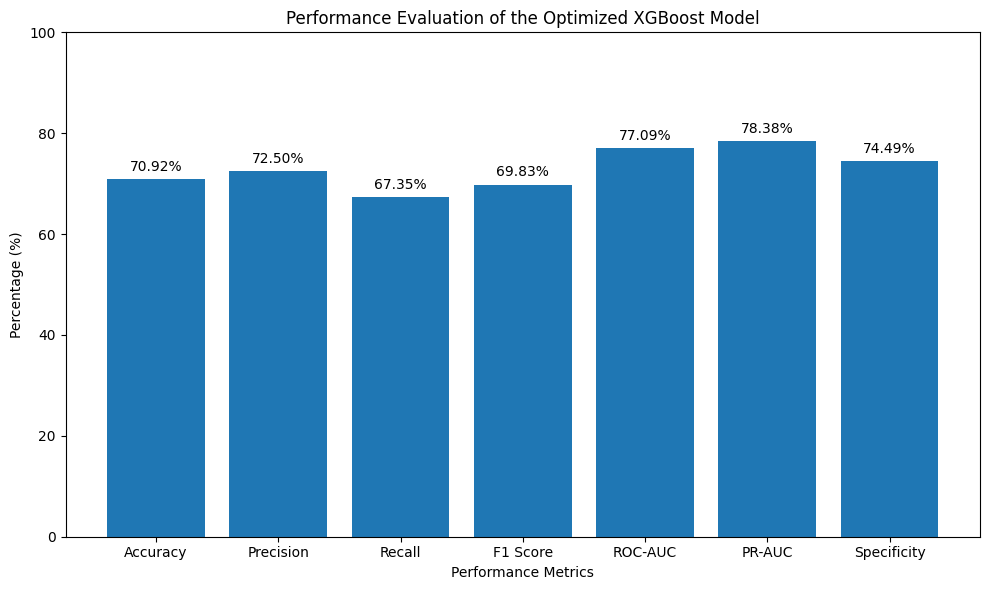

In [19]:
#performance evaluation of XGBoost Model
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC",
    "Specificity"
]

values = [
    70.92,
    72.50,
    67.35,
    69.83,
    77.09,
    78.38,
    74.49
]

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics, values)

plt.ylabel("Percentage (%)")
plt.xlabel("Performance Metrics")
plt.title("Performance Evaluation of the Optimized XGBoost Model")
plt.ylim(0, 100)

# Display values on top of bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

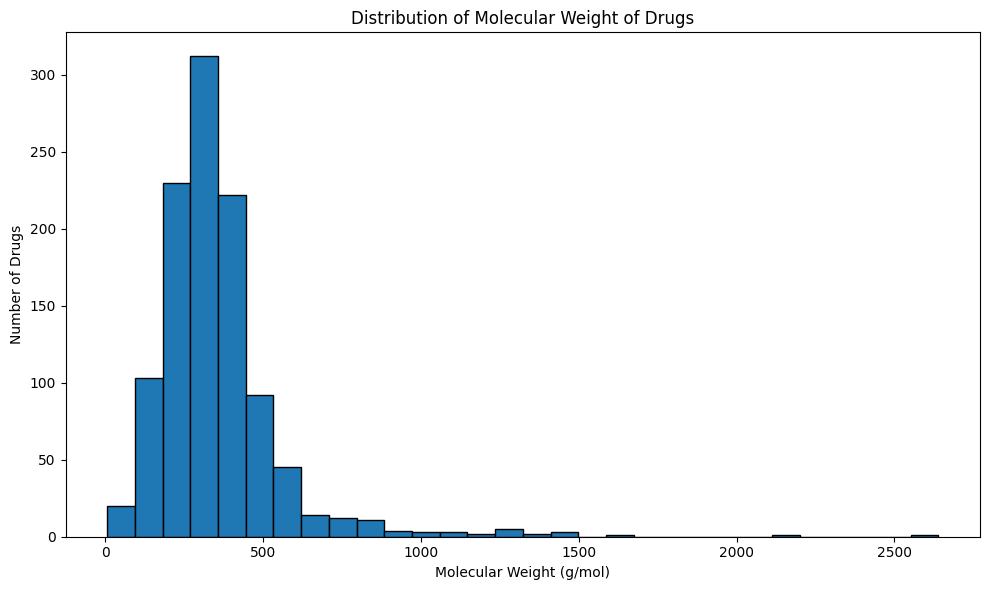

In [21]:
#distribution of molecular weight of drugs
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors

# Calculate molecular weight for each unique drug
drug_data = df[["DrugID", "DrugSmile"]].drop_duplicates().copy()

def calculate_mw(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return Descriptors.MolWt(mol)
    return None

drug_data["MolecularWeight"] = drug_data["DrugSmile"].apply(calculate_mw)

# Remove invalid values
mw = drug_data["MolecularWeight"].dropna()

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(
    mw,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Molecular Weight (g/mol)")
plt.ylabel("Number of Drugs")
plt.title("Distribution of Molecular Weight of Drugs")

plt.tight_layout()
plt.show()

Fingerprint matrix shape: (1086, 512)


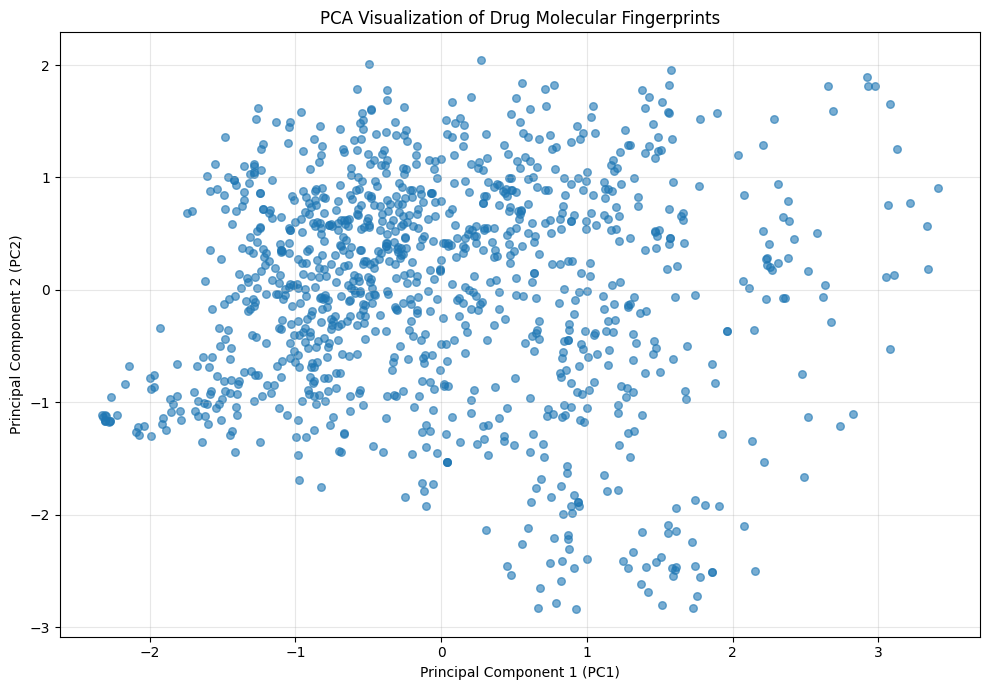

PC1 explained variance: 3.89%
PC2 explained variance: 3.11%
Total explained variance: 7.01%


In [27]:
#PCA Visualization of Drug Molecular Fingerprints
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA

# Get unique drugs
drug_data = df[["DrugID", "DrugSmile"]].drop_duplicates().copy()

# Morgan fingerprint generator
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=512
)

# Generate fingerprints
fingerprints = []

valid_indices = []

for idx, smiles in enumerate(drug_data["DrugSmile"]):
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        fp = morgan_generator.GetFingerprintAsNumPy(mol)
        fingerprints.append(fp)
        valid_indices.append(idx)

# Convert to NumPy array
X_fp = np.array(fingerprints)

print("Fingerprint matrix shape:", X_fp.shape)

# PCA: reduce 512 molecular features to 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_fp)

# Scatter plot
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.6,
    s=30
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA Visualization of Drug Molecular Fingerprints")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show explained variance
print(f"PC1 explained variance: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2 explained variance: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Total explained variance: {sum(pca.explained_variance_ratio_)*100:.2f}%")

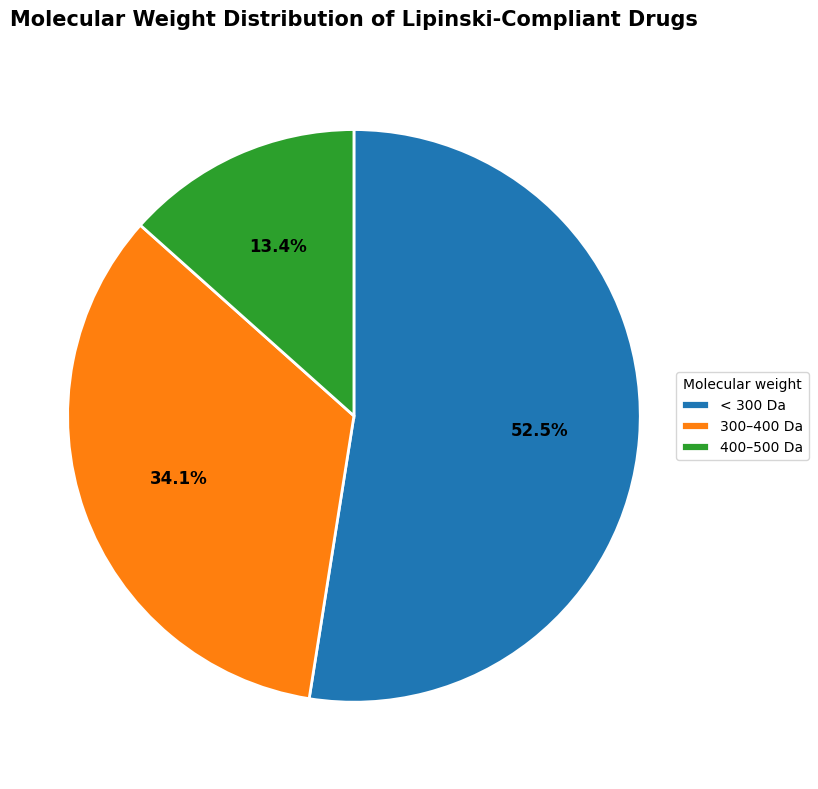

In [38]:
#Among the 866 drugs satisfying all four selected Lipinski criteria, 52.5% have a molecular weight below 300 Da, 34.1% fall between 300–400 Da, and 13.4% fall between 400–500 Da.
import matplotlib.pyplot as plt

labels = ["< 300 Da", "300–400 Da", "400–500 Da"]
values = [52.5, 34.1, 13.4]

fig, ax = plt.subplots(figsize=(8, 8))

wedges, _, autotexts = ax.pie(
    values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    }
)

for text in autotexts:
    text.set_fontsize(12)
    text.set_weight("bold")

ax.legend(
    wedges,
    labels,
    title="Molecular weight",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title(
    "Molecular Weight Distribution of Lipinski-Compliant Drugs",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.axis("equal")
plt.tight_layout()
plt.show()